In [3]:
from pathlib import Path
import pandas as pd

# Find all book and movie files
book_files = sorted(Path("../book_data").glob("book*_dialogue.csv"))
movie_files = sorted(Path("../movie_data").glob("hp*.csv"))

print("Book files:", len(book_files))
print("Movie files:", len(movie_files))


def load_files(files, version):

    frames = []

    for file in files:
        temp = pd.read_csv(file)

        temp["version"] = version
        temp["source_file"] = file.stem

        frames.append(temp)

    return pd.concat(frames, ignore_index=True)


books = load_files(book_files, "book")
movies = load_files(movie_files, "movie")

# Combine all dialogue
df = pd.concat([books, movies], ignore_index=True)

print(df.groupby("version").size())

Book files: 7
Movie files: 8
version
book     35550
movie     7445
dtype: int64


In [4]:
character_aliases = {
    "tom riddle": "Lord Voldemort",
    "tom marvolo riddle": "Lord Voldemort",
    "voldemort": "Lord Voldemort",
    "wormtail": "Peter Pettigrew",
    "barty crouch junior": "Barty Crouch Jr.",
    "barty crouch jr": "Barty Crouch Jr.",
    "professor quirrell": "Quirinus Quirrell"
}

def normalize_character(name):

    name = str(name).strip()
    key = name.lower()

    return character_aliases.get(key, name)


df["character"] = df["character"].apply(normalize_character)

In [5]:
from gensim.utils import simple_preprocess
from gensim.models import Word2Vec

# Tokenize all dialogue
df["tokens"] = df["dialog"].fillna("").apply(
    lambda x: simple_preprocess(
        str(x),
        deacc=True,
        min_len=1
    )
)

# Each dialogue turn is a separate training sequence
sentences = [
    tokens
    for tokens in df["tokens"]
    if len(tokens) >= 2
]

# Train one shared Word2Vec model
model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    negative=5,
    epochs=30,
    workers=1,
    seed=42
)

In [6]:
# Group by version and character, NOT by individual movie/book
character_docs = (
    df.groupby(["version", "character"], sort=False)["tokens"]
    .apply(
        lambda rows: [
            word
            for dialogue in rows
            for word in dialogue
        ]
    )
    .reset_index(name="tokens")
)

# Count total words per character
character_docs["word_count"] = (
    character_docs["tokens"].apply(len)
)

print(character_docs[
    ["version", "character", "word_count"]
].sort_values("word_count", ascending=False))

    version         character  word_count
9      book      Harry Potter       80110
14     book       Ron Weasley       43090
16     book  Hermione Granger       41130
1      book           Unknown       37670
2      book  Albus Dumbledore       24058
..      ...               ...         ...
145   movie      Bloody Baron           3
199   movie           Old man           2
122   movie             Snake           1
159   movie       Gryffindors           1
172   movie   Whomping Willow           1

[283 rows x 3 columns]


In [7]:
import numpy as np

from gensim.parsing.preprocessing import STOPWORDS
from sklearn.feature_extraction.text import TfidfVectorizer

# Preserve potentially interesting speaking-style words
preserve_words = {
    "i", "me", "my", "mine",
    "you", "your", "yours",
    "he", "him", "his",
    "she", "her",
    "we", "us", "our",
    "they", "them", "their",
    "not", "no", "never",
    "must", "should", "would",
    "could", "can", "will"
}

stop_words = set(STOPWORDS) - preserve_words

# Remove stopwords from each character document
character_docs["filtered_tokens"] = (
    character_docs["tokens"].apply(
        lambda tokens: [
            word for word in tokens
            if word not in stop_words
        ]
    )
)

# Convert documents to text
documents = character_docs["filtered_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

# Fit TF-IDF across all character/version documents
tfidf_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    lowercase=False,
    sublinear_tf=True,
    use_idf=True,
    smooth_idf=True,
    norm=None,
    max_df=0.90
)

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

feature_names = np.array(
    tfidf_vectorizer.get_feature_names_out()
)

In [8]:
weighted_character_embeddings = {}
embedding_coverage = {}

for i, row in character_docs.iterrows():

    key = (row["version"], row["character"])

    # Get TF-IDF weights for this character
    tfidf_row = tfidf_matrix.getrow(i)

    words = feature_names[tfidf_row.indices]
    weights = tfidf_row.data

    # Keep only words represented in Word2Vec
    valid = np.array([
        word in model.wv
        for word in words
    ])

    words = words[valid]
    weights = weights[valid]

    if len(words) == 0 or weights.sum() == 0:
        continue

    # Retrieve Word2Vec embeddings
    vectors = model.wv[list(words)]

    # Calculate weighted character embedding
    embedding = np.average(
        vectors,
        axis=0,
        weights=weights
    )

    weighted_character_embeddings[key] = embedding

    # Calculate vocabulary coverage
    eligible_tokens = row["filtered_tokens"]

    known_tokens = [
        word for word in eligible_tokens
        if word in model.wv
    ]

    embedding_coverage[key] = (
        len(known_tokens) / len(eligible_tokens)
        if eligible_tokens else 0
    )

In [9]:
for version in ["book", "movie"]:

    print(f"\nTOP 20 CHARACTERS - {version.upper()}")

    top = (
        character_docs[
            character_docs["version"] == version
        ]
        .nlargest(20, "word_count")
    )

    print(
        top[["character", "word_count"]].to_string(index=False)
    )


TOP 20 CHARACTERS - BOOK
         character  word_count
      Harry Potter       80110
       Ron Weasley       43090
  Hermione Granger       41130
           Unknown       37670
  Albus Dumbledore       24058
     Rubeus Hagrid       12433
     Severus Snape        9036
       Remus Lupin        8299
      Fred Weasley        6361
Minerva McGonagall        6282
     Molly Weasley        5733
      Sirius Black        5624
      Draco Malfoy        4894
   Cornelius Fudge        4445
    George Weasley        4124
  Dolores Umbridge        3764
         Ted Tonks        3445
     Alastor Moody        3283
     Ginny Weasley        3120
   Horace Slughorn        2905

TOP 20 CHARACTERS - MOVIE
         character  word_count
      Harry Potter       15051
  Hermione Granger        8207
  Albus Dumbledore        7814
       Ron Weasley        7494
     Rubeus Hagrid        3726
    Lord Voldemort        2828
     Severus Snape        2462
   Horace Slughorn        2294
Minerva McGonagal

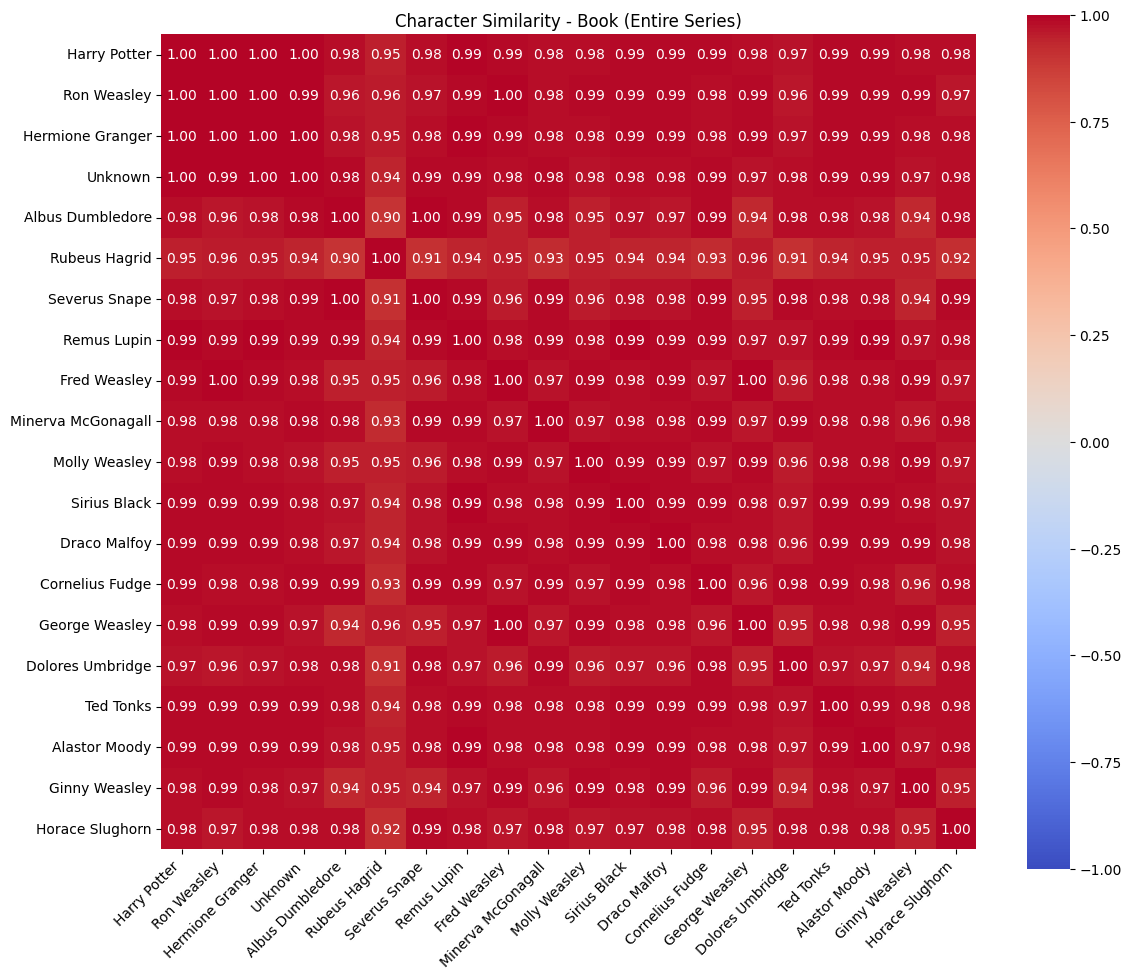

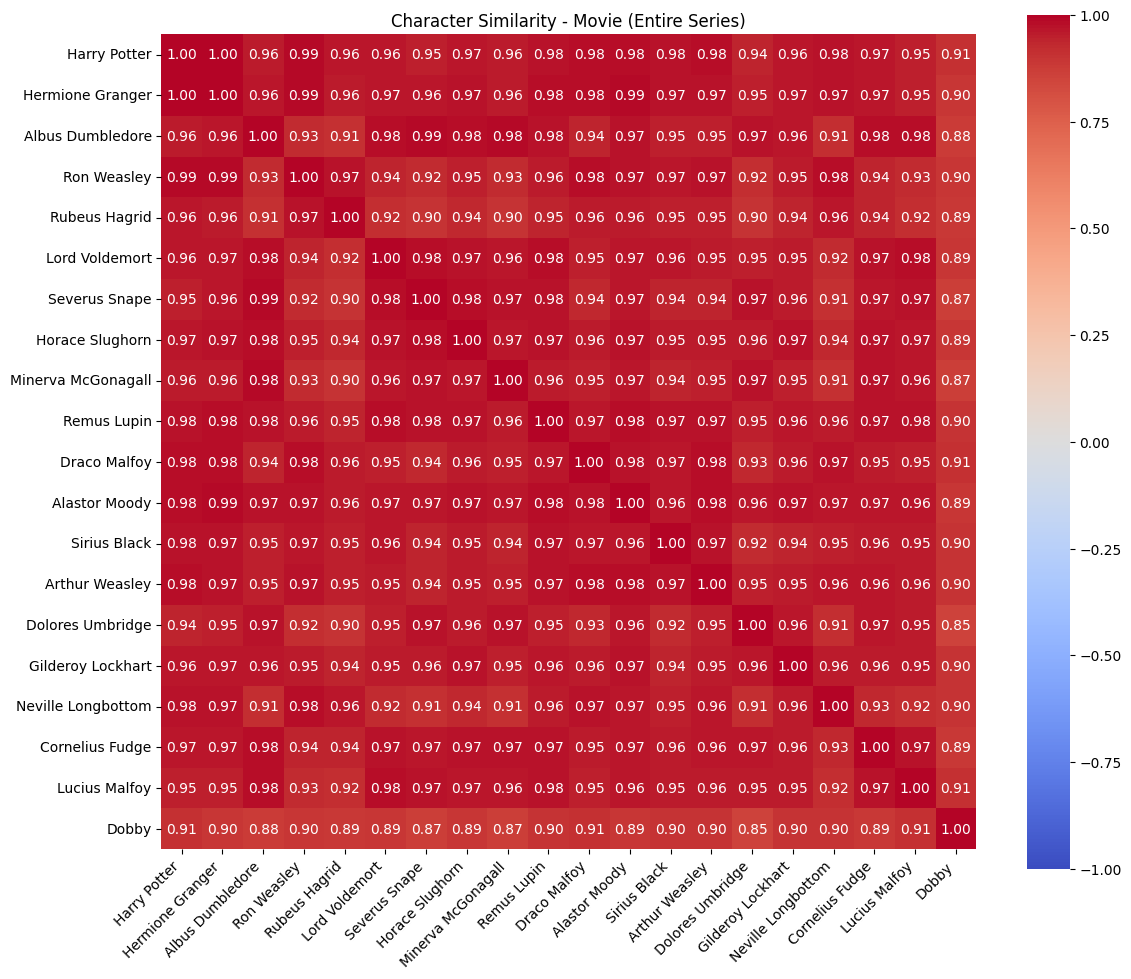

In [11]:
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns


def plot_character_heatmap(version, top_n=20):

    # Select top characters by total dialogue
    top = (
        character_docs[
            character_docs["version"] == version
        ]
        .nlargest(top_n, "word_count")
    )

    characters = [
        c for c in top["character"]
        if (version, c) in weighted_character_embeddings
    ]

    # Construct embedding matrix
    X = np.vstack([
        weighted_character_embeddings[(version, c)]
        for c in characters
    ])

    # Calculate cosine similarities
    similarities = cosine_similarity(X)
    
    similarity_df = pd.DataFrame(
        similarities,
        index=characters,
        columns=characters
    )

    # Plot
    plt.figure(figsize=(12, 10))

    sns.heatmap(
        similarity_df,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2f",
        square=True
    )

    plt.title(
        f"Character Similarity - {version.capitalize()} (Entire Series)"
    )

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    return similarity_df


book_similarity = plot_character_heatmap("book")
movie_similarity = plot_character_heatmap("movie")


BOOK
Minimum: 0.48118196511284944
Maximum: 0.9988589274044609
Mean: 0.8805839222373293
Median: 0.905542829594935
Standard deviation: 0.0847591352375908


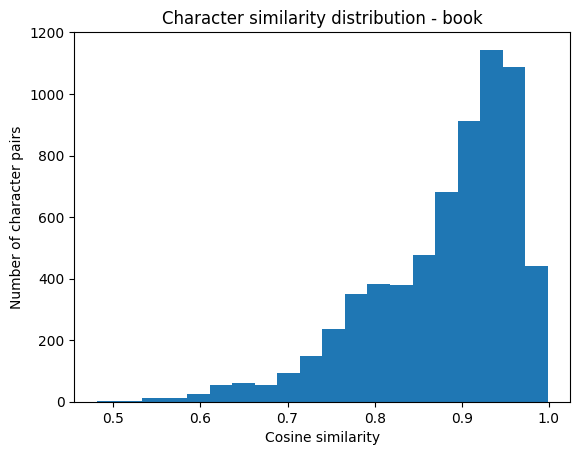


MOVIE
Minimum: 0.09677217242269523
Maximum: 0.9950949287620053
Mean: 0.7151199138005582
Median: 0.7351424153818429
Standard deviation: 0.15086247399119482


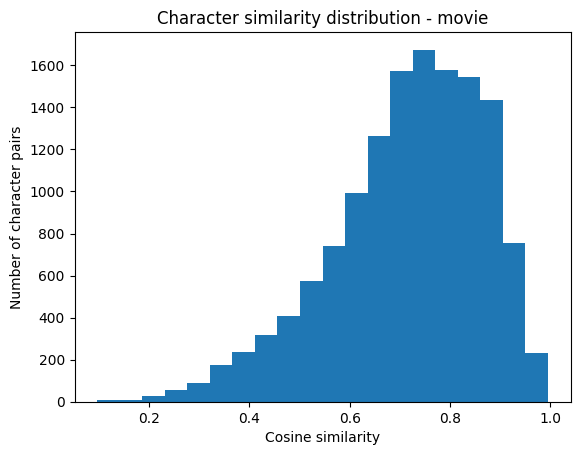

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

def inspect_similarity_distribution(embeddings, version):

    characters = [
        c for v, c in embeddings.keys()
        if v == version
    ]

    X = np.vstack([
        embeddings[(version, c)]
        for c in characters
    ])

    similarities = cosine_similarity(X)

    # Only take upper triangle, excluding diagonal
    values = similarities[
        np.triu_indices(len(characters), k=1)
    ]

    print(f"\n{version.upper()}")
    print("Minimum:", values.min())
    print("Maximum:", values.max())
    print("Mean:", values.mean())
    print("Median:", np.median(values))
    print("Standard deviation:", values.std())

    plt.hist(values, bins=20)
    plt.xlabel("Cosine similarity")
    plt.ylabel("Number of character pairs")
    plt.title(f"Character similarity distribution - {version}")
    plt.show()


inspect_similarity_distribution(
    weighted_character_embeddings, "book"
)

inspect_similarity_distribution(
    weighted_character_embeddings, "movie"
)

In [13]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

# 1. Collect all character embeddings
keys = list(weighted_character_embeddings.keys())

X = np.vstack([
    weighted_character_embeddings[key]
    for key in keys
])

# 2. Normalize each embedding
X_normalized = normalize(X)

# 3. Center the embeddings
X_centered = X_normalized - X_normalized.mean(axis=0)

# 4. Find the largest common component
pca = PCA(n_components=1)
pca.fit(X_centered)

# 5. Remove the first principal component
component_scores = pca.transform(X_centered)

common_component = (
    component_scores @ pca.components_
)

X_debiased = X_centered - common_component

# 6. Normalize again
X_debiased = normalize(X_debiased)

# 7. Rebuild dictionary
debiased_character_embeddings = {
    key: embedding
    for key, embedding in zip(keys, X_debiased)
}

print("Explained variance of first component:",
      pca.explained_variance_ratio_[0])

Explained variance of first component: 0.10500013575585317


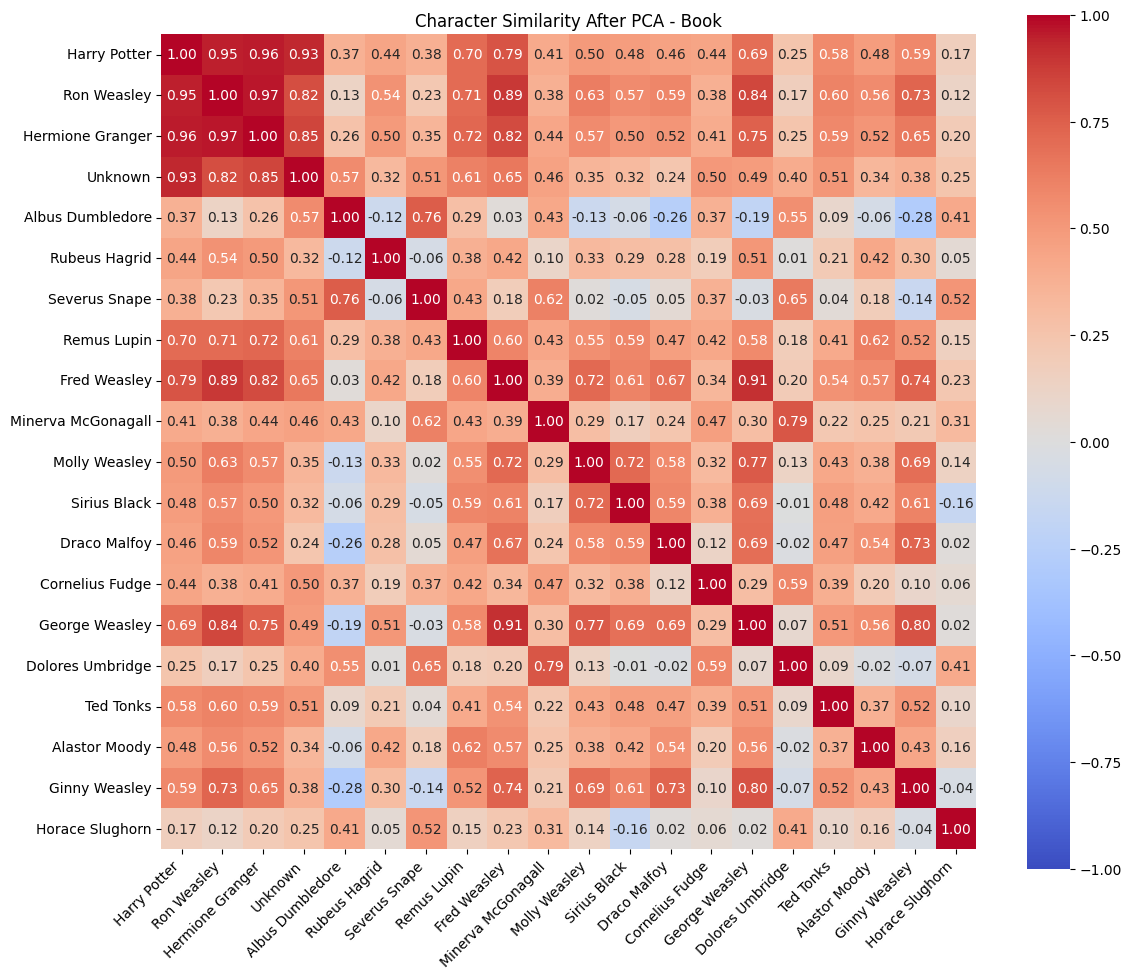

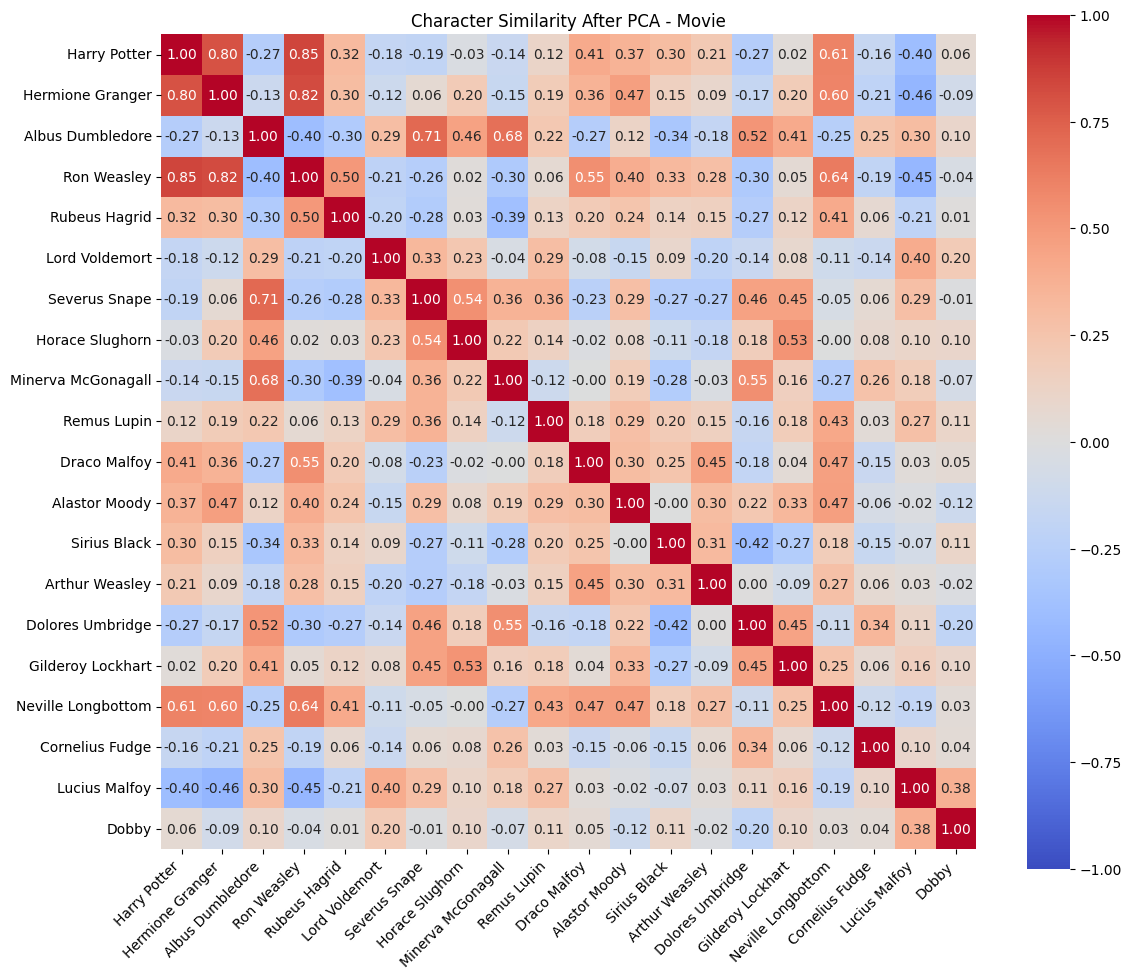

In [14]:
def plot_debiased_heatmap(version, top_n=20):

    # Select top characters by total dialogue
    top = (
        character_docs[
            character_docs["version"] == version
        ]
        .nlargest(top_n, "word_count")
    )

    characters = [
        c for c in top["character"]
        if (version, c) in debiased_character_embeddings
    ]

    X = np.vstack([
        debiased_character_embeddings[(version, c)]
        for c in characters
    ])

    similarity = cosine_similarity(X)

    similarity_df = pd.DataFrame(
        similarity,
        index=characters,
        columns=characters
    )

    plt.figure(figsize=(12, 10))

    sns.heatmap(
        similarity_df,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2f",
        square=True
    )

    plt.title(
        f"Character Similarity After PCA - {version.capitalize()}"
    )

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    return similarity_df


book_similarity_pca = plot_debiased_heatmap("book")
movie_similarity_pca = plot_debiased_heatmap("movie")